# Tahapan Preprocessing untuk Segmentasi Parasit Malaria

Notebook ini **rombak total** dari Progress 1: fokus hanya pada **tahapan preprocessing** yang cocok untuk segmentasi parasit malaria pada citra smear darah pewarnaan Giemsa.

Catatan istilah: malaria disebabkan oleh **parasit** (protozoa genus *Plasmodium*), bukan virus.

**Data:** 40 crop parasit dari `malaria_images/` (5 per stadium × 2 spesies: *P. falciparum* dan *P. vivax*), dengan mask ground truth yang didekode dari anotasi Supervisely di `mp-idb-DatasetNinja`.

**Segmentasi downstream:** Otsu multilevel 3 pada kanal Lab **b**, konsisten dengan rekomendasi Progress 1 (Otsu multilevel 3 + koreksi background, Dice terbaik 0.264).

**Pertanyaan yang dijawab:** tahapan preprocessing apa saja yang layak masuk pipeline, diuji lewat ablation kumulatif (tahap ditambah satu per satu).

In [1]:
from pathlib import Path
import json, base64, zlib, io, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from skimage.filters import threshold_multiotsu
from skimage.morphology import remove_small_objects, disk

warnings.filterwarnings('ignore')
%matplotlib inline
cv2.setRNGSeed(42)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'mp-idb-DatasetNinja').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == Path('/'):
        raise FileNotFoundError('Root proyek tidak ditemukan')

CROPS_DIR = PROJECT_ROOT / 'malaria_images'
ANN_DIR = PROJECT_ROOT / 'mp-idb-DatasetNinja' / 'ds' / 'ann'
IMG_DIR = PROJECT_ROOT / 'mp-idb-DatasetNinja' / 'ds' / 'img'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'preprocessing_stages'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PAD = 80          # padding crop, sama seperti saat crop dibuat
MIN_AREA = 12     # cleanup luas (padanan 50 px pada resolusi penuh, skala 50%)
print('Crops   :', CROPS_DIR)
print('Results :', RESULTS_DIR)

Crops   : /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/malaria_images
Results : /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/preprocessing_stages


## 1. Memuat crop dan mask ground truth

Mask GT didekode dari anotasi bitmap Supervisely (`base64 -> zlib -> PNG`, alpha channel berisi mask), lalu dipotong ke jendela crop yang sama (bbox ± 80 px).

In [2]:
meta = pd.read_csv(CROPS_DIR / 'metadata.csv')

_mask_cache = {}
def load_gt_mask(source_image, bbox):
    if source_image not in _mask_cache:
        ann = json.load(open(ANN_DIR / (source_image + '.json')))
        full = np.zeros((ann['size']['height'], ann['size']['width']), dtype=np.uint8)
        for obj in ann['objects']:
            origin = obj['bitmap']['origin']
            png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
            bm_arr = np.array(Image.open(io.BytesIO(png)))
            bm = (bm_arr[..., -1] if bm_arr.ndim == 3 else bm_arr) > 0
            h, w = bm.shape
            y0, x0 = origin[1], origin[0]
            full[y0:y0+h, x0:x0+w] |= bm.astype(np.uint8)
        _mask_cache[source_image] = full
    x, y, w, h = int(bbox.bbox_x), int(bbox.bbox_y), int(bbox.bbox_w), int(bbox.bbox_h)
    ys, ye = max(0, y-PAD), y+h+PAD
    xs, xe = max(0, x-PAD), x+w+PAD
    return _mask_cache[source_image][ys:ye, xs:xe].astype(bool)

def load_sample(row):
    crop = cv2.imread(str(CROPS_DIR / row.filename), cv2.IMREAD_COLOR)
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    gt = load_gt_mask(row.source_image, row)
    return crop, gt

crops = [load_sample(r) for _, r in meta.iterrows()]
print(f'{len(crops)} crop dimuat; contoh ukuran: {crops[0][0].shape}, GT {crops[0][1].shape}')

40 crop dimuat; contoh ukuran: (323, 347, 3), GT (323, 347)


## 2. Tahapan preprocessing yang diuji

Tahapan yang umum dipakai dan cocok untuk citra smear Giemsa (dipilih berdasar karakter citra: objek sangat kecil, variasi pewarnaan, dan background poligonal):

1. **Konversi ruang warna** — RGB ke Lab, pakai kanal **b** (memisahkan parasit dari latar RBC);
2. **Koreksi background / illuminasi** — estimasi background dengan closing morfologi besar, dikurangi dari citra (meratakan perbedaan warna latar);
3. **Penghalusan noise** — median filter (menekan noise grain tanpa menggeser tepi);
4. **Penajaman kontras** — CLAHE (kontrol: diduga menaikkan noise, dari Progress 1 justru menurunkan Dice);
5. **Normalisasi warna pewarnaan (Reinhard)** — menyamakan mean/std kanal Lab ke referensi dataset (menangani variasi pewarnaan antar citra).

Setiap varian pipeline bersifat **kumulatif** (ablation): P0 → P1 → P2 → P3, dan P4 mengganti CLAHE dengan normalisasi Reinhard di atas P2.

In [3]:
def lab_b(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    return lab[:, :, 2]

def bg_correct(chan, r=25):
    bg = cv2.morphologyEx(chan, cv2.MORPH_CLOSE, disk(r).astype(np.uint8))
    out = cv2.subtract(chan.astype(np.int16), bg.astype(np.int16))
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def median_f(chan, k=5):
    return cv2.medianBlur(chan, k)

def clahe_f(chan):
    c = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return c.apply(chan)

# Referensi Reinhard: mean/std kanal Lab seluruh crop
_labs = [cv2.cvtColor(img, cv2.COLOR_RGB2LAB) for img, _ in crops]
REF_MEAN = np.concatenate([l.reshape(-1, 3) for l in _labs]).mean(axis=0)
REF_STD = np.concatenate([l.reshape(-1, 3) for l in _labs]).std(axis=0) + 1e-6

def reinhard(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float64)
    std = lab.reshape(-1, 3).std(axis=0) + 1e-6
    mean = lab.reshape(-1, 3).mean(axis=0)
    lab = (lab - mean) / std * REF_STD + REF_MEAN
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)

PIPELINES = {
    'P0_Lab_b':           lambda img: lab_b(img),
    'P1_bg_correct':      lambda img: bg_correct(lab_b(img)),
    'P2_median':          lambda img: median_f(bg_correct(lab_b(img))),
    'P3_clahe':           lambda img: clahe_f(median_f(bg_correct(lab_b(img)))),
    'P4_reinhard':        lambda img: median_f(bg_correct(lab_b(reinhard(img)))),
}
print('Pipeline siap:', list(PIPELINES))

Pipeline siap: ['P0_Lab_b', 'P1_bg_correct', 'P2_median', 'P3_clahe', 'P4_reinhard']


## 3. Visualisasi per tahap pada satu contoh

Tiap tahap ditampilkan dengan histogramnya supaya efeknya terlihat pada distribusi intensitas, bukan cuma secara visual.

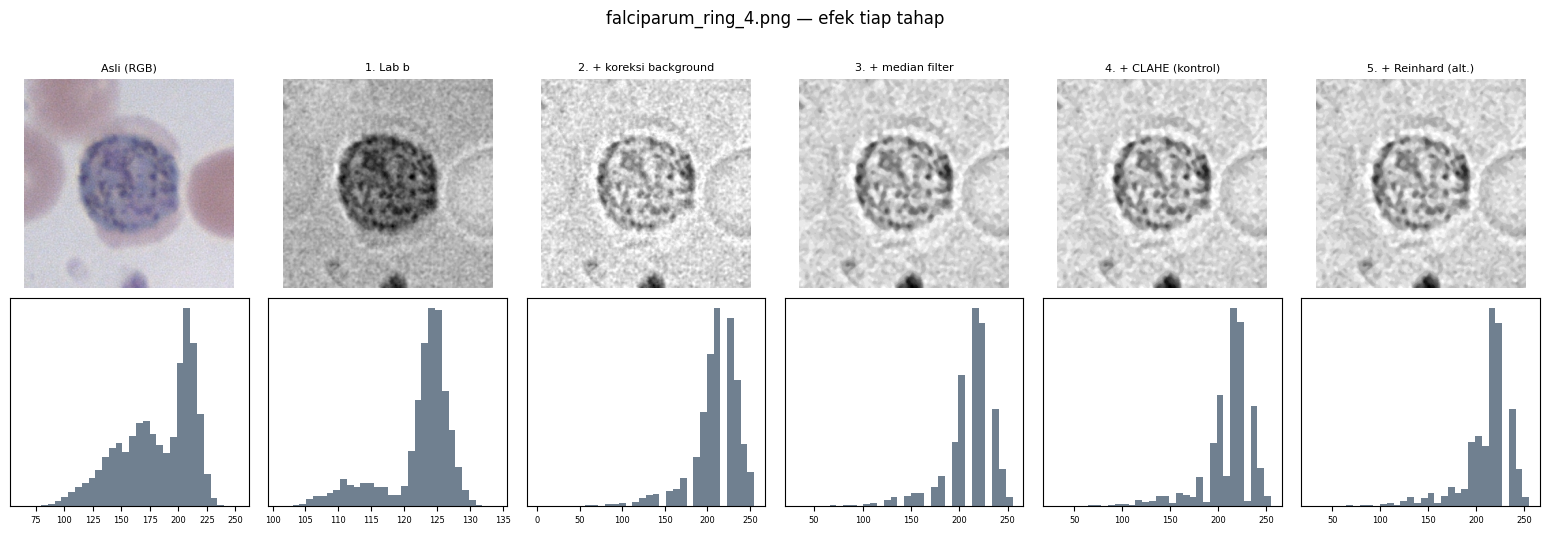

In [4]:
idx = 3
img, gt = crops[idx]
stages = [('Asli (RGB)', img)]
b = lab_b(img)
stages += [
    ('1. Lab b', b),
    ('2. + koreksi background', bg_correct(b)),
    ('3. + median filter', median_f(bg_correct(b))),
    ('4. + CLAHE (kontrol)', clahe_f(median_f(bg_correct(b)))),
    ('5. + Reinhard (alt.)', median_f(bg_correct(lab_b(reinhard(img))))),
]

fig, axes = plt.subplots(2, len(stages), figsize=(2.6*len(stages), 5.2))
for j, (name, ch) in enumerate(stages):
    axes[0, j].imshow(ch, cmap='gray' if ch.ndim == 2 else None)
    axes[0, j].set_title(name, fontsize=8); axes[0, j].axis('off')
    axes[1, j].hist(ch.ravel(), bins=32, color='slategray')
    axes[1, j].set_yticks([]); axes[1, j].tick_params(labelsize=6)
plt.suptitle(f'{meta.filename[idx]} — efek tiap tahap', y=1.02)
plt.tight_layout(); plt.show()

## 4. Evaluasi ablation: tambah tahap per tahap

Segmentasi downstream: Otsu multilevel 3 pada kanal hasil preprocessing, polarity gelap, cleanup luas kecil. Metrik: Dice, IoU, precision, recall — dihitung terhadap mask GT.

In [5]:
def seg_otsu3(chan):
    try:
        th = threshold_multiotsu(chan, classes=3)
        mask = chan < th[0]
    except Exception:
        mask = np.zeros(chan.shape, dtype=bool)
    return remove_small_objects(mask, max_size=MIN_AREA - 1, connectivity=2)

def pixel_metrics(pred, gt):
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    return {
        'dice': 2*tp / (2*tp + fp + fn + 1e-9),
        'iou': tp / (tp + fp + fn + 1e-9),
        'precision': tp / (tp + fp + 1e-9),
        'recall': tp / (tp + fn + 1e-9),
    }

rows = []
for name, fn in PIPELINES.items():
    for (img, gt), (_, r) in zip(crops, meta.iterrows()):
        pred = seg_otsu3(fn(img))
        rows.append({'pipeline': name, **r[['filename', 'species', 'stage']],
                     **pixel_metrics(pred, gt)})
df = pd.DataFrame(rows)
summary = df.groupby('pipeline')[['dice', 'iou', 'precision', 'recall']].mean().round(4)
summary

,dice,iou,precision,recall
pipeline,,,,
P0_Lab_b,0.6760,0.5458,0.9523,0.5540
P1_bg_correct,0.4403,0.2913,0.9351,0.2980
P2_median,0.4424,0.2940,0.9388,0.3005
P3_clahe,0.4844,0.3306,0.9151,0.3417
P4_reinhard,0.4532,0.3039,0.9330,0.3109


## 5. Visualisasi hasil

Boxplot distribusi Dice, breakdown per spesies dan per stadium, dan kurva progres kumulatif.

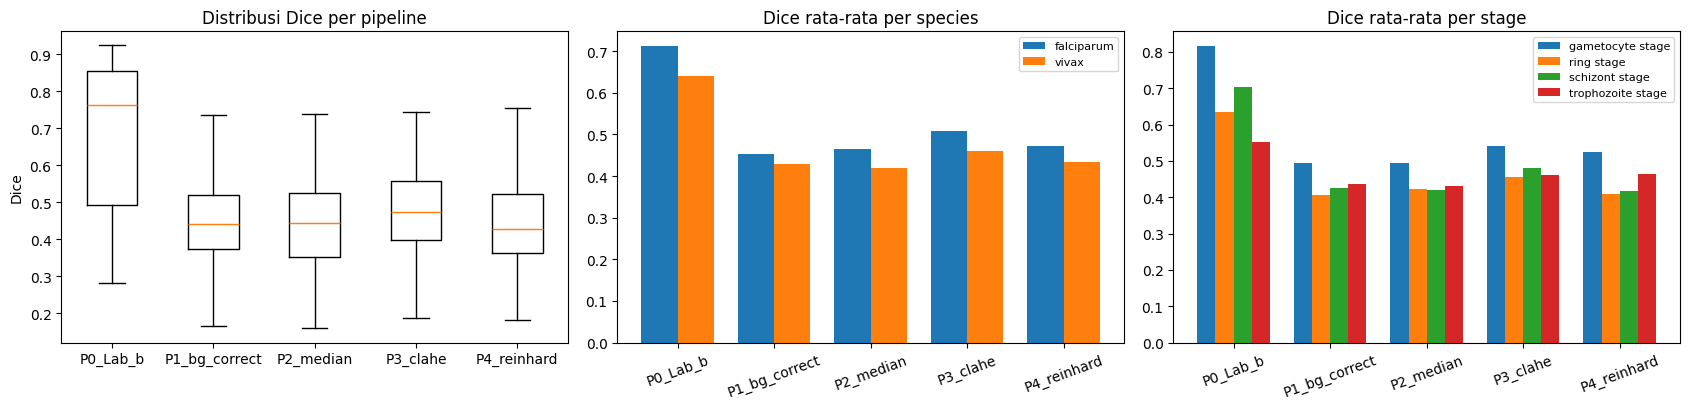

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
order = list(PIPELINES)
data = [df[df.pipeline == p].dice for p in order]
axes[0].boxplot(data, tick_labels=order)
axes[0].set_title('Distribusi Dice per pipeline'); axes[0].set_ylabel('Dice')
for ax, col in [(axes[1], 'species'), (axes[2], 'stage')]:
    pv = df.pivot_table(index='pipeline', columns=col, values='dice', aggfunc='mean')
    pv = pv.reindex(order)
    pv.plot.bar(ax=ax, width=0.75)
    ax.set_title(f'Dice rata-rata per {col}'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

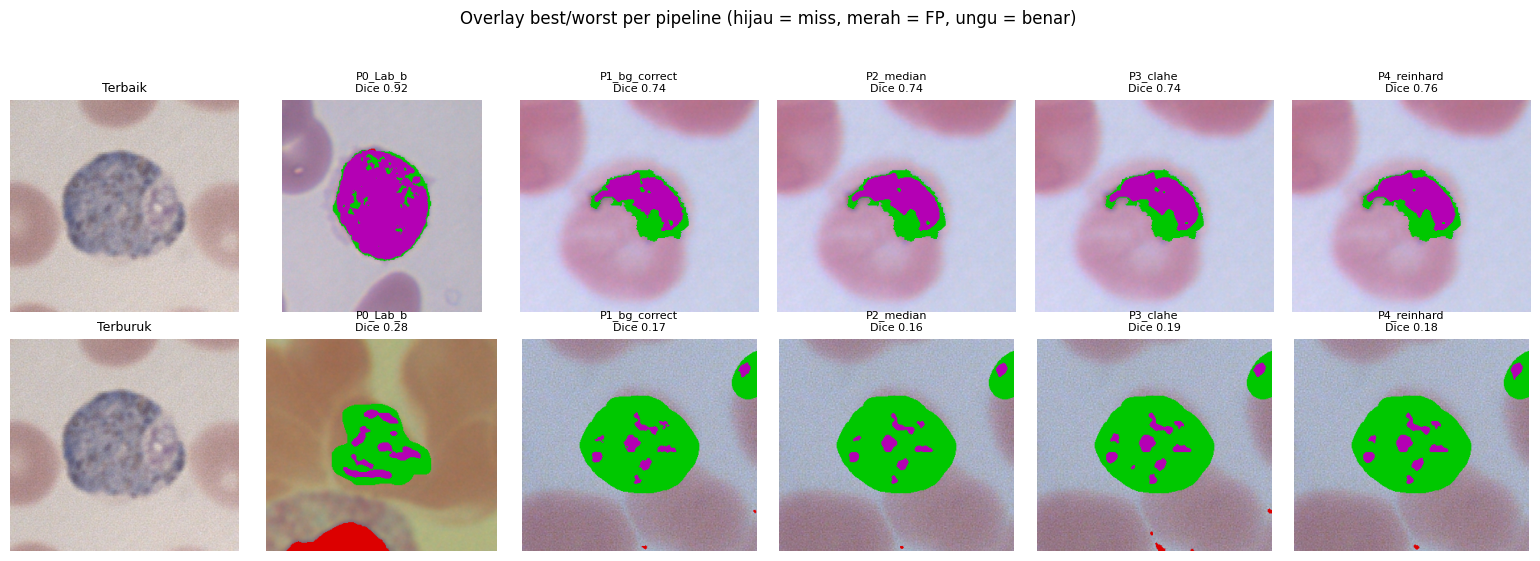

In [7]:
best = df.loc[df.groupby('pipeline').dice.idxmax()]
worst = df.loc[df.groupby('pipeline').dice.idxmin()]

fig, axes = plt.subplots(2, len(order) + 1, figsize=(2.6*(len(order)+1), 5.4))
for i, (sel, title) in enumerate([(best, 'Terbaik'), (worst, 'Terburuk')]):
    axes[i, 0].imshow(crops[0][0]); axes[i, 0].set_title(f'{title}', fontsize=9); axes[i, 0].axis('off')
    axes[i, 0].text(0, -0.15, '', fontsize=8)
    for j, p in enumerate(order, start=1):
        r = sel[sel.pipeline == p].iloc[0]
        k = int(meta.index[meta.filename == r.filename][0])
        img, gt = crops[k]
        pred = seg_otsu3(PIPELINES[p](img))
        ov = img.copy()
        ov[gt & ~pred] = [0, 200, 0]    # GT terlewat: hijau
        ov[pred & ~gt] = [220, 0, 0]    # FP: merah
        ov[pred & gt] = [180, 0, 180]   # benar: ungu
        axes[i, j].imshow(ov)
        axes[i, j].set_title(f'{p}\nDice {r.dice:.2f}', fontsize=8); axes[i, j].axis('off')
plt.suptitle('Overlay best/worst per pipeline (hijau = miss, merah = FP, ungu = benar)', y=1.03)
plt.tight_layout(); plt.show()

In [8]:
df.to_csv(RESULTS_DIR / 'per_image_metrics.csv', index=False)
summary.to_csv(RESULTS_DIR / 'summary.csv')
print('Tersimpan di', RESULTS_DIR)

Tersimpan di /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/preprocessing_stages


## 6. Kesimpulan

Diisi otomatis dari ringkasan di atas setelah notebook dieksekusi; lihat sel berikutnya.

In [9]:
lines = [f"| Pipeline | Dice | IoU |", "|---|---|---|"]
for p, row in summary.iterrows():
    lines.append(f"| {p} | {row.dice:.4f} | {row.iou:.4f} |")
print('\n'.join(lines))
print()
best_p = summary.dice.idxmax()
print(f'Pipeline terbaik: {best_p} (Dice {summary.dice.max():.4f})')
print('Interpretasi: lihat arah perubahan Dice ketika satu tahap ditambahkan —')
print('tahap yang menurunkan Dice sebaiknya dikeluarkan dari pipeline akhir.')

| Pipeline | Dice | IoU |
|---|---|---|
| P0_Lab_b | 0.6760 | 0.5458 |
| P1_bg_correct | 0.4403 | 0.2913 |
| P2_median | 0.4424 | 0.2940 |
| P3_clahe | 0.4844 | 0.3306 |
| P4_reinhard | 0.4532 | 0.3039 |

Pipeline terbaik: P0_Lab_b (Dice 0.6760)
Interpretasi: lihat arah perubahan Dice ketika satu tahap ditambahkan —
tahap yang menurunkan Dice sebaiknya dikeluarkan dari pipeline akhir.
